In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
DATA_PATH = "../data/Telco-Customer-Churn.csv"

In [2]:
df = pd.read_csv(DATA_PATH)

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
print("Missing values per column (NaN):")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("(empty above means no true NaNs)\n")

print("Fully duplicated rows:", df.duplicated().sum())
print("Unique customerIDs:", df["customerID"].nunique(), "of", len(df))

Missing values per column (NaN):
Series([], dtype: int64)
(empty above means no true NaNs)

Fully duplicated rows: 0
Unique customerIDs: 7043 of 7043


In [5]:
blank_mask = df["TotalCharges"].astype(str).str.strip() == ""
print("Blank TotalCharges entries:", blank_mask.sum())

df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Blank TotalCharges entries: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


       count  percent
Churn                
No      5174    73.46
Yes     1869    26.54


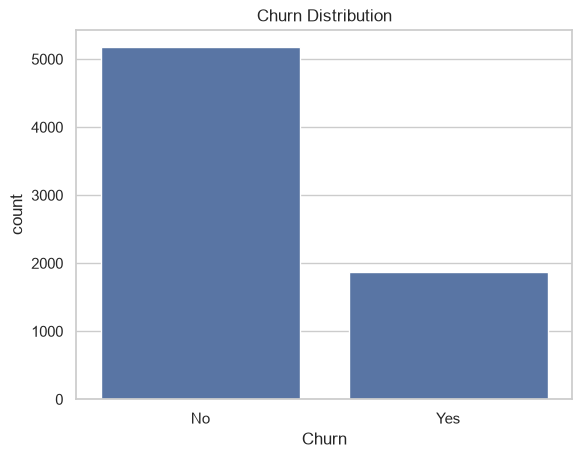

In [6]:
counts = df["Churn"].value_counts()
percent = df["Churn"].value_counts(normalize=True).mul(100).round(2)

print(pd.DataFrame({"count": counts, "percent": percent}))

sns.countplot(data=df, x="Churn")
plt.title("Churn Distribution")
plt.show()

In [7]:
print("Numerical summary:")
display(df.describe())

print("\nUnique values in categorical columns:")
for col in df.select_dtypes(exclude="number").columns:
    if col not in ["customerID", "TotalCharges"]:
        print(f"{col:20s} -> {df[col].unique().tolist()}")

Numerical summary:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



Unique values in categorical columns:
gender               -> ['Female', 'Male']
Partner              -> ['Yes', 'No']
Dependents           -> ['No', 'Yes']
PhoneService         -> ['No', 'Yes']
MultipleLines        -> ['No phone service', 'No', 'Yes']
InternetService      -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity       -> ['No', 'Yes', 'No internet service']
OnlineBackup         -> ['Yes', 'No', 'No internet service']
DeviceProtection     -> ['No', 'Yes', 'No internet service']
TechSupport          -> ['No', 'Yes', 'No internet service']
StreamingTV          -> ['No', 'Yes', 'No internet service']
StreamingMovies      -> ['No', 'Yes', 'No internet service']
Contract             -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling     -> ['Yes', 'No']
PaymentMethod        -> ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn                -> ['No', 'Yes']


In [8]:
import sys
sys.path.append("..")   # lets the notebook import from src/

from src.preprocessing import load_data, clean_data

raw = load_data(DATA_PATH)
df_clean = clean_data(raw)
print("Cleaning finished without errors.")

Cleaning finished without errors.


In [9]:
print("Shape before:", raw.shape, "-> after:", df_clean.shape)
print("Total missing values:", df_clean.isnull().sum().sum())
print("TotalCharges dtype:", df_clean["TotalCharges"].dtype)
print("Churn counts:", df_clean["Churn"].value_counts().to_dict())
print("customerID still present:", "customerID" in df_clean.columns)
print("Duplicate feature rows (after dropping ID):", df_clean.duplicated().sum())

print("\nThe 11 originally-blank rows, now cleaned:")
blank_rows = raw["TotalCharges"].str.strip() == ""
display(df_clean.loc[blank_rows, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

df_clean.describe()

Shape before: (7043, 21) -> after: (7043, 20)
Total missing values: 0
TotalCharges dtype: float64
Churn counts: {0: 5174, 1: 1869}
customerID still present: False
Duplicate feature rows (after dropping ID): 22

The 11 originally-blank rows, now cleaned:


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,0.0,0
753,0,20.25,0.0,0
936,0,80.85,0.0,0
1082,0,25.75,0.0,0
1340,0,56.05,0.0,0
3331,0,19.85,0.0,0
3826,0,25.35,0.0,0
4380,0,20.00,0.0,0
5218,0,19.70,0.0,0
6670,0,73.35,0.0,0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304,0.265370
std,0.368612,24.559481,30.090047,2266.794470,0.441561
min,0.000000,0.000000,18.250000,0.000000,0.000000
25%,0.000000,9.000000,35.500000,398.550000,0.000000
50%,0.000000,29.000000,70.350000,1394.550000,0.000000
75%,0.000000,55.000000,89.850000,3786.600000,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


Overall churn rate: 26.54%

Contract


,customers,churn_rate
Contract,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83


PaymentMethod


,customers,churn_rate
PaymentMethod,,
Electronic check,2365,45.29
Mailed check,1612,19.11
Bank transfer (automatic),1544,16.71
Credit card (automatic),1522,15.24


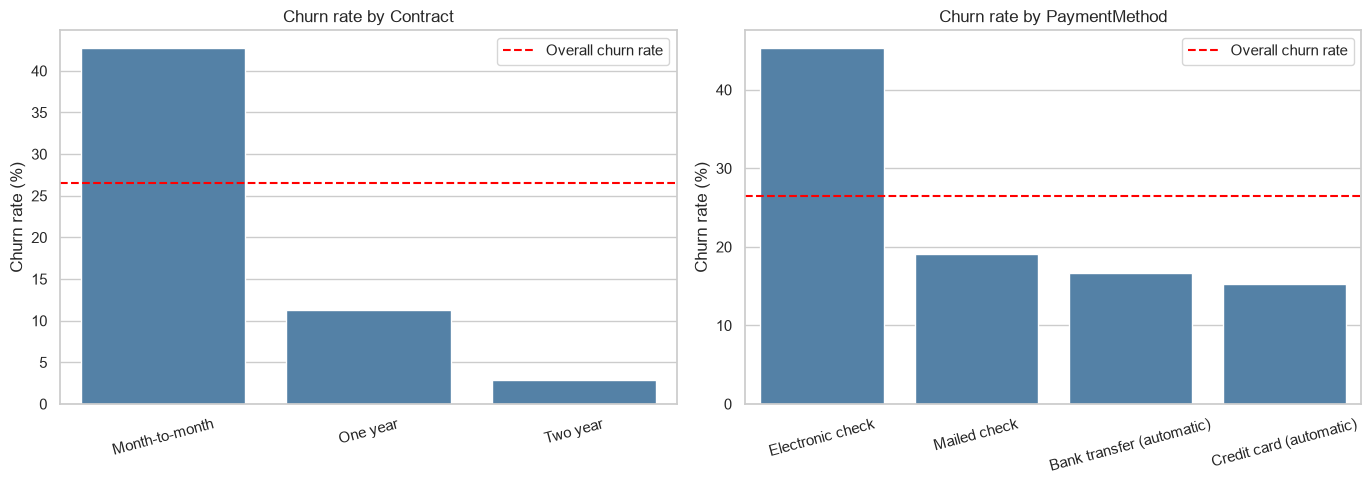

In [10]:
def churn_rate_table(data, col):
    """Customer count and churn rate (%) for each category in `col`."""
    t = data.groupby(col)["Churn"].agg(customers="count", churn_rate="mean")
    t["churn_rate"] = (t["churn_rate"] * 100).round(2)
    return t.sort_values("churn_rate", ascending=False)

overall = df_clean["Churn"].mean() * 100
print(f"Overall churn rate: {overall:.2f}%\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["Contract", "PaymentMethod"]):
    t = churn_rate_table(df_clean, col)
    print(col)
    display(t)
    sns.barplot(data=t.reset_index(), x=col, y="churn_rate", ax=ax, color="steelblue")
    ax.axhline(overall, ls="--", color="red", label="Overall churn rate")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
    ax.legend()
plt.tight_layout()
plt.show()

Churn rate by tenure band (months):


,customers,churn_rate
tenure,,
0-12,2186,47.44
13-24,1024,28.71
25-48,1594,20.39
49-72,2239,9.51


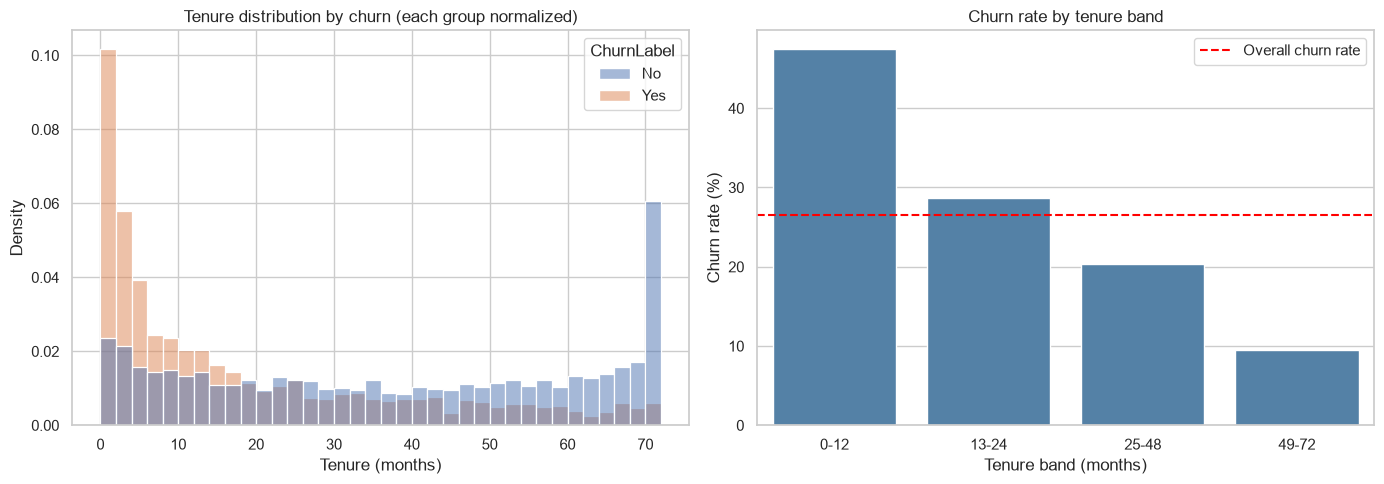

In [11]:
plot_df = df_clean.assign(ChurnLabel=df_clean["Churn"].map({0: "No", 1: "Yes"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=plot_df, x="tenure", hue="ChurnLabel", bins=36,
             stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Tenure distribution by churn (each group normalized)")
axes[0].set_xlabel("Tenure (months)")

tenure_bins = pd.cut(df_clean["tenure"], bins=[-1, 12, 24, 48, 72],
                     labels=["0-12", "13-24", "25-48", "49-72"])
t = (df_clean.groupby(tenure_bins, observed=True)["Churn"]
     .agg(customers="count", churn_rate="mean"))
t["churn_rate"] = (t["churn_rate"] * 100).round(2)
print("Churn rate by tenure band (months):")
display(t)

sns.barplot(data=t.reset_index(), x="tenure", y="churn_rate", ax=axes[1], color="steelblue")
axes[1].axhline(overall, ls="--", color="red", label="Overall churn rate")
axes[1].set_title("Churn rate by tenure band")
axes[1].set_xlabel("Tenure band (months)")
axes[1].set_ylabel("Churn rate (%)")
axes[1].legend()
plt.tight_layout()
plt.show()

MonthlyCharges summary by churn group:


,count,mean,std,min,25%,50%,75%,max
ChurnLabel,,,,,,,,
No,5174.0,61.27,31.09,18.25,25.10,64.43,88.4,118.75
Yes,1869.0,74.44,24.67,18.85,56.15,79.65,94.2,118.35


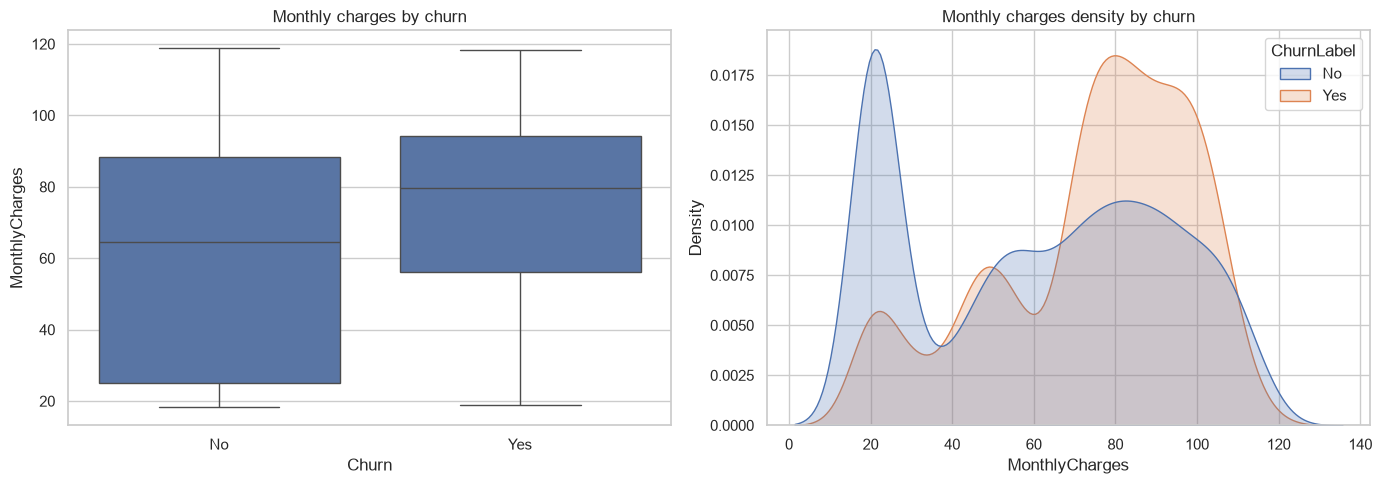

In [12]:
print("MonthlyCharges summary by churn group:")
display(plot_df.groupby("ChurnLabel")["MonthlyCharges"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=plot_df, x="ChurnLabel", y="MonthlyCharges", ax=axes[0])
axes[0].set_title("Monthly charges by churn")
axes[0].set_xlabel("Churn")

sns.kdeplot(data=plot_df, x="MonthlyCharges", hue="ChurnLabel",
            common_norm=False, fill=True, ax=axes[1])
axes[1].set_title("Monthly charges density by churn")
plt.tight_layout()
plt.show()

In [13]:
import importlib, src.preprocessing as prep
importlib.reload(prep)   # picks up edits to preprocessing.py

X_train, X_test, y_train, y_test = prep.get_train_test_split(df_clean)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Train churn rate: %.2f%%" % (y_train.mean() * 100))
print("Test churn rate:  %.2f%%" % (y_test.mean() * 100))
print("Index overlap between train and test:", len(set(X_train.index) & set(X_test.index)))

numeric_cols, categorical_cols = prep.get_column_types(X_train)
print("\nNumeric columns:", numeric_cols)
print("Categorical columns (%d):" % len(categorical_cols), categorical_cols)

X_train: (5634, 19) | X_test: (1409, 19)
Train churn rate: 26.54%
Test churn rate:  26.54%
Index overlap between train and test: 0

Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [14]:
preprocessor = prep.build_preprocessor(numeric_cols, categorical_cols)

Xt_train = preprocessor.fit_transform(X_train)   # fit on TRAIN only
Xt_test = preprocessor.transform(X_test)         # transform only, no fitting

print("Transformed train shape:", Xt_train.shape)
print("Transformed test shape: ", Xt_test.shape)
print("NaNs in transformed train:", np.isnan(Xt_train).sum())

# Scaled numeric columns of the train set should have mean ~0 and std ~1
print("Train numeric means (should be ~0):", Xt_train[:, :len(numeric_cols)].mean(axis=0).round(3))
print("Train numeric stds  (should be ~1):", Xt_train[:, :len(numeric_cols)].std(axis=0).round(3))

Transformed train shape: (5634, 45)
Transformed test shape:  (1409, 45)
NaNs in transformed train: 0
Train numeric means (should be ~0): [ 0. -0. -0. -0.]
Train numeric stds  (should be ~1): [1. 1. 1. 1.]


In [15]:
import importlib
import src.train as train_mod
import src.evaluate as eval_mod
importlib.reload(train_mod)
importlib.reload(eval_mod)

models = train_mod.get_models(numeric_cols, categorical_cols)

results = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)          # preprocessing is fitted inside, on train only
    results.append(eval_mod.evaluate_model(name, pipe, X_train, y_train, X_test, y_test))

results_df = pd.DataFrame(results).set_index("model").round(4)
results_df["acc_gap"] = (results_df["train_accuracy"] - results_df["test_accuracy"]).round(4)
display(results_df)

,train_accuracy,test_accuracy,precision,recall,f1,roc_auc,acc_gap
model,,,,,,,
Logistic Regression,0.8056,0.8055,0.6572,0.5588,0.6040,0.8421,0.0001
Logistic Regression (balanced),0.7528,0.7381,0.5043,0.7834,0.6136,0.8416,0.0147
Decision Tree,0.8039,0.7984,0.6347,0.5668,0.5989,0.8297,0.0055
Decision Tree (balanced),0.7636,0.7544,0.5260,0.7567,0.6206,0.8318,0.0092
Random Forest,0.8608,0.8041,0.6725,0.5107,0.5805,0.8411,0.0567
Random Forest (balanced),0.8314,0.7615,0.5351,0.7754,0.6332,0.8409,0.0699


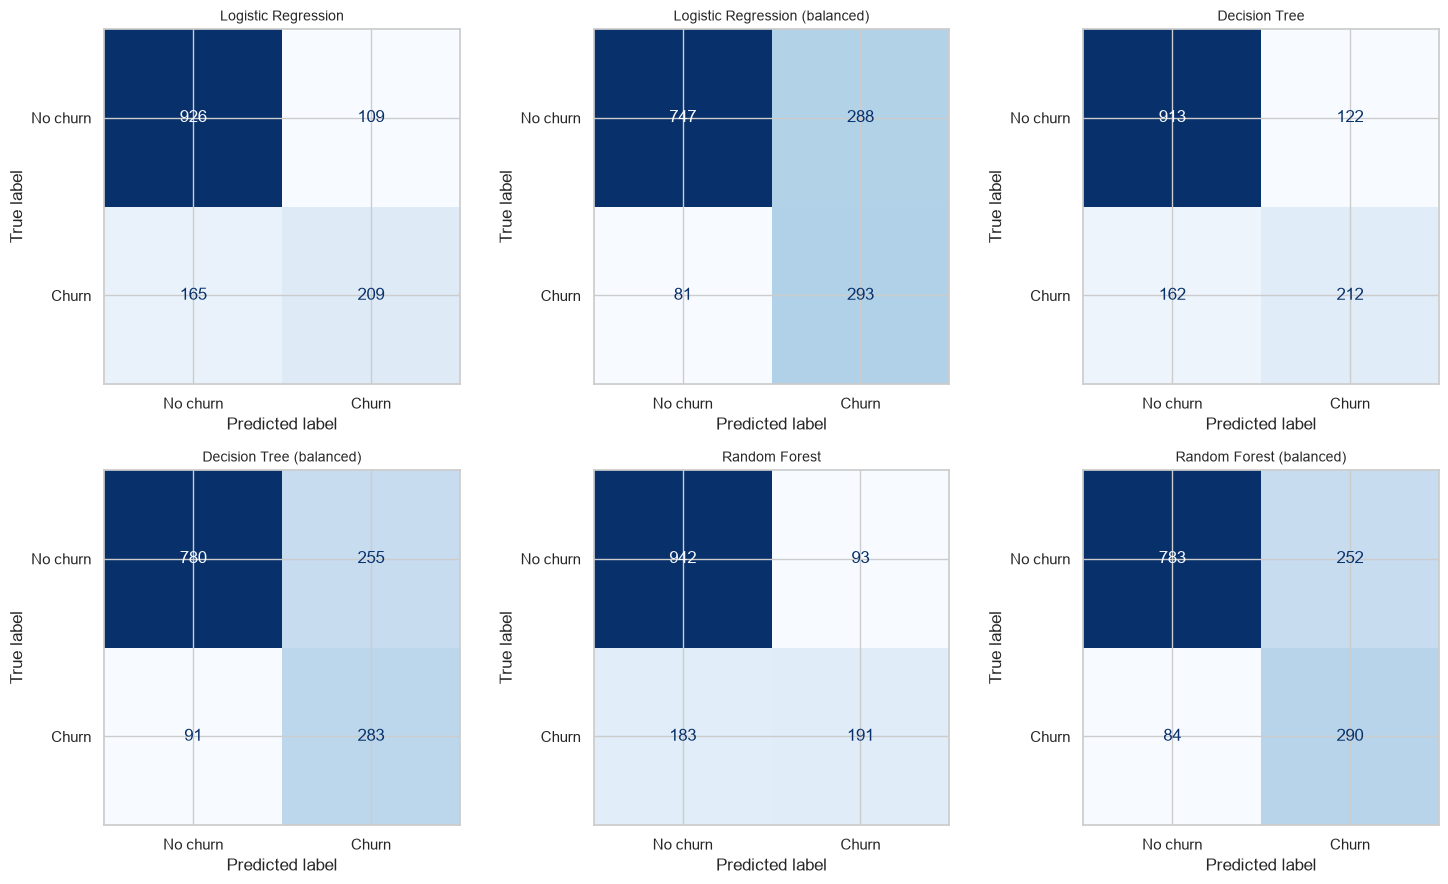

In [16]:
importlib.reload(eval_mod)
eval_mod.plot_confusion_matrices(models, X_test, y_test, list(models.keys()))

In [17]:
for name in ["Logistic Regression", "Logistic Regression (balanced)"]:
    eval_mod.print_report(name, models[name], X_test, y_test)

=== Logistic Regression ===
              precision    recall  f1-score   support

    No churn      0.849     0.895     0.871      1035
       Churn      0.657     0.559     0.604       374

    accuracy                          0.806      1409
   macro avg      0.753     0.727     0.738      1409
weighted avg      0.798     0.806     0.800      1409

=== Logistic Regression (balanced) ===
              precision    recall  f1-score   support

    No churn      0.902     0.722     0.802      1035
       Churn      0.504     0.783     0.614       374

    accuracy                          0.738      1409
   macro avg      0.703     0.753     0.708      1409
weighted avg      0.797     0.738     0.752      1409



In [18]:
from sklearn.metrics import confusion_matrix

COST_FN = 500   # ASSUMPTION: cost of losing a churner we failed to flag (lost revenue)
COST_FP = 300    # ASSUMPTION: cost of a retention offer sent to someone who wasn't leaving

rows = []
for name, pipe in models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pipe.predict(X_test)).ravel()
    rows.append({"model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                 "assumed_cost": fn * COST_FN + fp * COST_FP})

cost_df = pd.DataFrame(rows).set_index("model")
display(cost_df.sort_values("assumed_cost"))

,TN,FP,FN,TP,assumed_cost
model,,,,,
Logistic Regression,926,109,165,209,115200
Decision Tree,913,122,162,212,117600
Random Forest (balanced),783,252,84,290,117600
Random Forest,942,93,183,191,119400
Decision Tree (balanced),780,255,91,283,122000
Logistic Regression (balanced),747,288,81,293,126900


In [19]:
import joblib
importlib.reload(eval_mod)

saved = joblib.load("../models/churn_model.pkl")
nb_pipe = models["Logistic Regression (balanced)"]

p_saved = saved.predict_proba(X_test)[:, 1]
p_nb = nb_pipe.predict_proba(X_test)[:, 1]

print("Max abs difference in predicted probabilities:", np.abs(p_saved - p_nb).max())
print("Identical class predictions:", bool((saved.predict(X_test) == nb_pipe.predict(X_test)).all()))
print("Identical coefficients:", np.allclose(saved.named_steps["model"].coef_,
                                             nb_pipe.named_steps["model"].coef_))

Max abs difference in predicted probabilities: 0.0
Identical class predictions: True
Identical coefficients: True


,feature,coefficient,odds_ratio,abs_coef
0,tenure,-1.154,0.315,1.154
1,Contract_Two year,-0.776,0.460,0.776
2,InternetService_Fiber optic,0.708,2.030,0.708
3,MonthlyCharges,-0.676,0.509,0.676
4,Contract_Month-to-month,0.658,1.930,0.658
5,InternetService_DSL,-0.622,0.537,0.622
6,TotalCharges,0.490,1.632,0.490
7,TechSupport_No internet service,-0.275,0.759,0.275
8,DeviceProtection_No internet service,-0.275,0.759,0.275
9,InternetService_No,-0.275,0.759,0.275


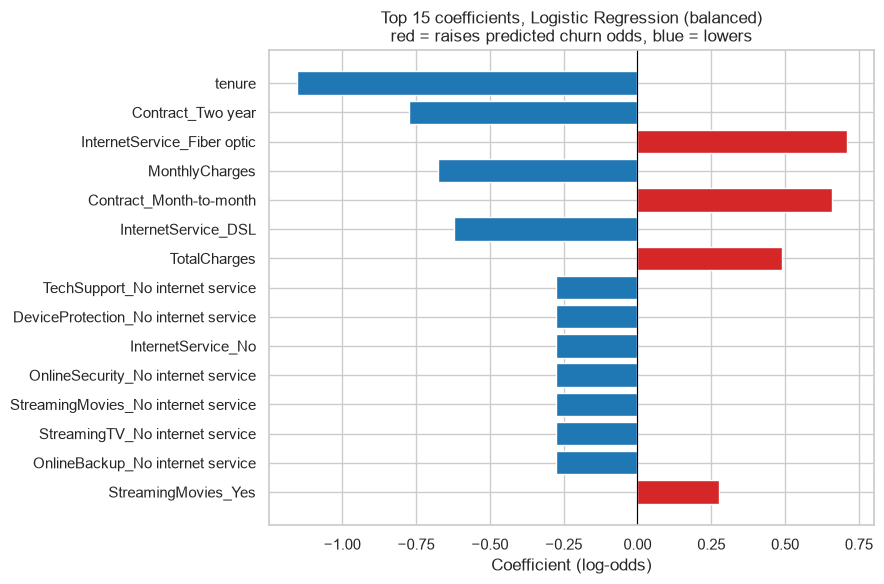

In [20]:
coef_df = eval_mod.coefficient_table(saved)
display(coef_df.head(15).round(3))

top = coef_df.head(15).iloc[::-1]
colors = ["tab:red" if c > 0 else "tab:blue" for c in top["coefficient"]]
plt.figure(figsize=(9, 6))
plt.barh(top["feature"], top["coefficient"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Top 15 coefficients, Logistic Regression (balanced)\nred = raises predicted churn odds, blue = lowers")
plt.xlabel("Coefficient (log-odds)")
plt.tight_layout()
plt.show()

In [21]:
rf_pipe = models["Random Forest (balanced)"]
imp_t = eval_mod.impurity_importance_table(rf_pipe, categorical_cols)

print("Top 15 transformed (one-hot) columns:")
display(imp_t.sort_values("importance", ascending=False).head(15).round(4))

imp_by_feature = imp_t.groupby("feature")["importance"].sum().sort_values(ascending=False)
print("\nSummed per original feature:")
display(imp_by_feature.round(4).to_frame("impurity_importance"))

Top 15 transformed (one-hot) columns:


,transformed_feature,importance,feature
1,tenure,0.1326,tenure
36,Contract_Month-to-month,0.1215,Contract
3,TotalCharges,0.0983,TotalCharges
2,MonthlyCharges,0.0728,MonthlyCharges
38,Contract_Two year,0.0632,Contract
18,OnlineSecurity_No,0.0626,OnlineSecurity
27,TechSupport_No,0.0537,TechSupport
16,InternetService_Fiber optic,0.0481,InternetService
43,PaymentMethod_Electronic check,0.0390,PaymentMethod
21,OnlineBackup_No,0.0197,OnlineBackup



Summed per original feature:


,impurity_importance
feature,
Contract,0.2027
tenure,0.1326
TotalCharges,0.0983
OnlineSecurity,0.0826
TechSupport,0.0738
MonthlyCharges,0.0728
InternetService,0.0722
PaymentMethod,0.0595
OnlineBackup,0.0332


In [22]:
perm_lr = eval_mod.permutation_importance_table(saved, X_test, y_test)
perm_rf = eval_mod.permutation_importance_table(rf_pipe, X_test, y_test)

print("Logistic Regression (balanced): drop in test ROC-AUC when a column is shuffled")
display(perm_lr.round(4))
print("Random Forest (balanced):")
display(perm_rf.round(4))

Logistic Regression (balanced): drop in test ROC-AUC when a column is shuffled


,importance_mean,importance_std
tenure,0.1578,0.0077
InternetService,0.0435,0.0066
Contract,0.0406,0.0043
MonthlyCharges,0.0396,0.0055
TotalCharges,0.0125,0.0030
StreamingMovies,0.0045,0.0018
StreamingTV,0.0041,0.0026
OnlineSecurity,0.0038,0.0016
PaymentMethod,0.0033,0.0017
TechSupport,0.0033,0.0016


Random Forest (balanced):


,importance_mean,importance_std
Contract,0.0626,0.0056
tenure,0.0284,0.0030
InternetService,0.0173,0.0044
TotalCharges,0.0150,0.0018
OnlineSecurity,0.0045,0.0019
TechSupport,0.0037,0.0019
PaymentMethod,0.0020,0.0015
PaperlessBilling,0.0016,0.0014
StreamingMovies,0.0014,0.0016
OnlineBackup,0.0011,0.0017


,RF_impurity_rank,RF_permutation_rank,LR_permutation_rank
tenure,2,2,1
InternetService,7,3,2
Contract,1,1,3
MonthlyCharges,6,12,4
TotalCharges,3,4,5
StreamingMovies,10,9,6
StreamingTV,13,18,7
OnlineSecurity,4,5,8
PaymentMethod,8,7,9
TechSupport,5,6,10


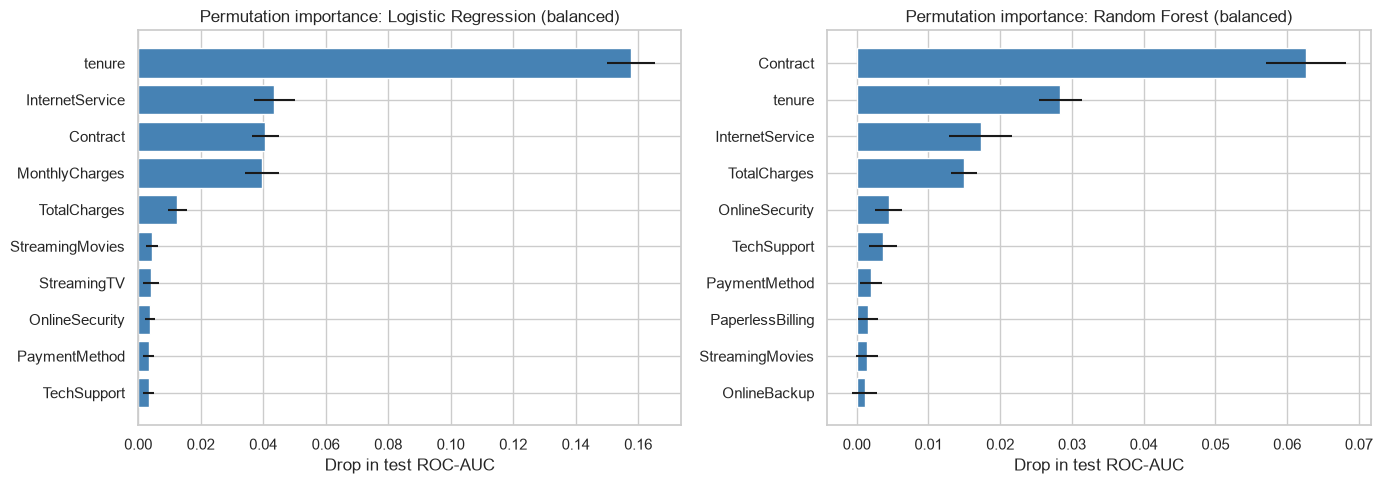

In [23]:
cmp = pd.DataFrame({
    "RF_impurity": imp_by_feature,
    "RF_permutation": perm_rf["importance_mean"],
    "LR_permutation": perm_lr["importance_mean"],
})
ranks = cmp.rank(ascending=False).astype(int).add_suffix("_rank")
display(ranks.sort_values("LR_permutation_rank"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=False)
for ax, (title, tbl) in zip(axes, [("Logistic Regression (balanced)", perm_lr),
                                   ("Random Forest (balanced)", perm_rf)]):
    top = tbl.head(10).iloc[::-1]
    ax.barh(top.index, top["importance_mean"], xerr=top["importance_std"], color="steelblue")
    ax.set_title(f"Permutation importance: {title}")
    ax.set_xlabel("Drop in test ROC-AUC")
plt.tight_layout()
plt.show()